# Task 63. Demonstrate Convolution Neural Network

The linked guide explains CNNs step by step (input image, convolution kernel, stride,
padding, pooling, and the fully connected classification layer) without code.
Each idea is shown in code below, then a small CNN is trained with Keras.

RGB image shape: (427, 640, 3)
Grayscale shape: (427, 640)


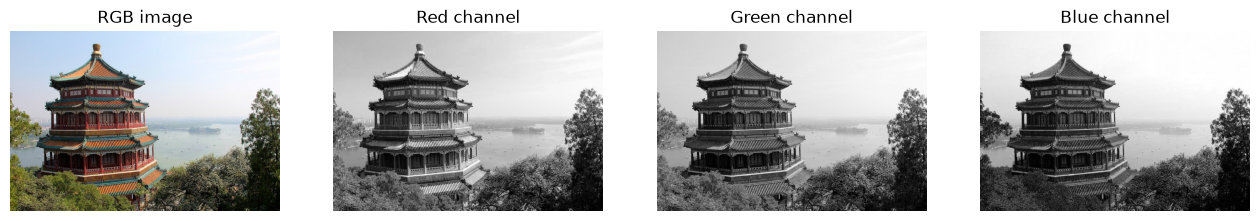

In [1]:
# ===== The input image =====
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image

rgb = load_sample_image('china.jpg')          # 427 x 640 x 3 (RGB channels)
gray = rgb.mean(axis=2) / 255.0               # one channel, values 0-1
print("RGB image shape:", rgb.shape)
print("Grayscale shape:", gray.shape)

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
axes[0].imshow(rgb); axes[0].set_title('RGB image')
for i, name in enumerate(['Red', 'Green', 'Blue']):
    axes[i + 1].imshow(rgb[:, :, i], cmap='gray'); axes[i + 1].set_title(name + ' channel')
for ax in axes:
    ax.axis('off')
plt.show()

In [2]:
# ===== The convolution layer: kernel / filter =====
def convolve2d(image, kernel, stride=1, padding=0):
    """Slide the kernel over the image and take the sum of element-wise products."""
    if padding > 0:
        image = np.pad(image, padding)
    k = kernel.shape[0]
    out_h = (image.shape[0] - k) // stride + 1
    out_w = (image.shape[1] - k) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i * stride:i * stride + k, j * stride:j * stride + k]
            out[i, j] = np.sum(patch * kernel)
    return out

# a 5x5 image and a 3x3 kernel, like the example in the guide
image = np.array([[1, 1, 1, 0, 0],
                  [0, 1, 1, 1, 0],
                  [0, 0, 1, 1, 1],
                  [0, 0, 1, 1, 0],
                  [0, 1, 1, 0, 0]])
kernel = np.array([[1, 0, 1],
                   [0, 1, 0],
                   [1, 0, 1]])

print("Convolved feature:\n", convolve2d(image, kernel))

Convolved feature:
 [[4. 3. 4.]
 [2. 4. 3.]
 [2. 3. 4.]]


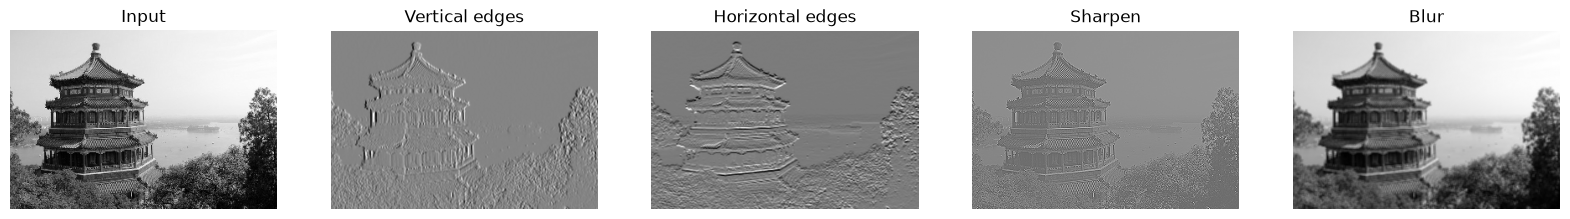

In [3]:
# ===== Kernels that detect features =====
kernels = {
    'Vertical edges': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    'Horizontal edges': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    'Sharpen': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    'Blur': np.ones((3, 3)) / 9,
}

small = gray[::2, ::2]   # half size so the pure-Python loop is quick
fig, axes = plt.subplots(1, 5, figsize=(20, 3))
axes[0].imshow(small, cmap='gray'); axes[0].set_title('Input')
for ax, (name, k) in zip(axes[1:], kernels.items()):
    ax.imshow(convolve2d(small, k), cmap='gray')
    ax.set_title(name)
for ax in axes:
    ax.axis('off')
plt.show()

In [4]:
# ===== Stride and padding =====
# valid padding: output is smaller than the input
print("No padding, stride 1:", convolve2d(image, kernel).shape)
# same padding: add a border of zeros so the output keeps the input size
print("Same padding, stride 1:", convolve2d(image, kernel, padding=1).shape)
# a stride of 2 moves the kernel two pixels at a time
print("Same padding, stride 2:", convolve2d(image, kernel, stride=2, padding=1).shape)

No padding, stride 1: (3, 3)
Same padding, stride 1: (5, 5)
Same padding, stride 2: (3, 3)


RGB input: (107, 160, 3) -> one feature map: (105, 158)


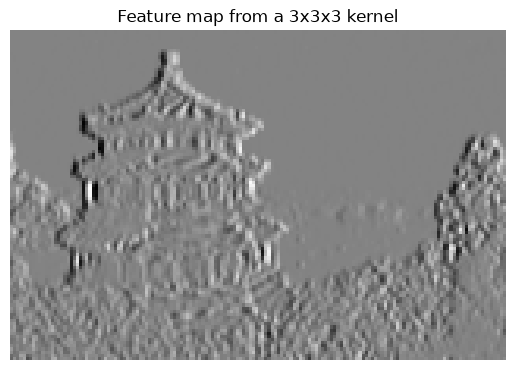

In [5]:
# ===== Convolution over several channels =====
# a kernel for an RGB image has depth 3; the results of each channel are added together
rgb_small = rgb[::4, ::4] / 255.0
kernel_3d = np.stack([kernels['Vertical edges']] * 3, axis=2)
feature_map = sum(convolve2d(rgb_small[:, :, c], kernel_3d[:, :, c]) for c in range(3))
print("RGB input:", rgb_small.shape, "-> one feature map:", feature_map.shape)
plt.imshow(feature_map, cmap='gray'); plt.axis('off'); plt.title('Feature map from a 3x3x3 kernel');

In [6]:
# ===== The pooling layer =====
def pool2d(image, size=2, stride=2, mode='max'):
    out_h = (image.shape[0] - size) // stride + 1
    out_w = (image.shape[1] - size) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i * stride:i * stride + size, j * stride:j * stride + size]
            out[i, j] = patch.max() if mode == 'max' else patch.mean()
    return out

feature = np.array([[3, 3, 2, 1, 0, 1],
                    [0, 0, 1, 3, 1, 2],
                    [3, 1, 2, 2, 3, 0],
                    [2, 0, 0, 2, 2, 1],
                    [2, 0, 0, 0, 1, 3],
                    [1, 2, 3, 1, 0, 2]])
print("Max pooling:\n", pool2d(feature, mode='max'))
print("Average pooling:\n", pool2d(feature, mode='avg'))

Max pooling:
 [[3. 3. 2.]
 [3. 2. 3.]
 [2. 3. 3.]]
Average pooling:
 [[1.5  1.75 1.  ]
 [1.5  1.5  1.5 ]
 [1.25 1.   1.5 ]]


In [7]:
# ===== Flatten + fully connected layer =====
pooled = pool2d(feature, mode='max')
flat = pooled.flatten()
print("Flattened vector:", flat)

rng = np.random.default_rng(0)
W_fc = rng.normal(size=(flat.size, 3))       # fully connected layer with 3 classes
scores = flat @ W_fc
probs = np.exp(scores - scores.max()) / np.exp(scores - scores.max()).sum()
print("Class probabilities (softmax):", probs.round(3))

Flattened vector: [3. 3. 2. 3. 2. 3. 2. 3. 3.]
Class probabilities (softmax): [0.952 0.018 0.03 ]


In [8]:
# ===== Putting it together: a CNN in Keras (Fashion-MNIST) =====
import tensorflow as tf
from tensorflow.keras import layers, models

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train = x_train[..., None] / 255.0
x_test = x_test[..., None] / 255.0
class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print(x_train.shape, x_test.shape)

    0/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

16384/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 8us/step

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 5us/step


       0/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/26421880 ━━━━━━━━━━━━━━━━━━━━ 4:26 10us/step

   32768/26421880 ━━━━━━━━━━━━━━━━━━━━ 2:59 7us/step 

... (431 outputs left out)

4300800/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

4399104/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step


(60000, 28, 28, 1) (10000, 28, 28, 1)


In [9]:
tf.random.set_seed(42)
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),   # convolution
    layers.MaxPooling2D((2, 2)),                                     # pooling
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),                                                # flatten
    layers.Dense(128, activation='relu'),                            # fully connected
    layers.Dense(10, activation='softmax')                           # classification
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1)

Epoch 1/3


  1/422 ━━━━━━━━━━━━━━━━━━━━ 19:40 3s/step - accuracy: 0.0547 - loss: 2.3074

  3/422 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - accuracy: 0.2370 - loss: 2.1961

  5/422 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.2984 - loss: 2.1020

  7/422 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - accuracy: 0.3549 - loss: 1.9872

  9/422 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.3880 - loss: 1.8726

... (638 outputs left out)

418/422 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9013 - loss: 0.2736

420/422 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9014 - loss: 0.2734

422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9015 - loss: 0.2731

422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.9015 - loss: 0.2731 - val_accuracy: 0.9002 - val_loss: 0.2782


In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", test_acc)

Test accuracy: 0.895799994468689


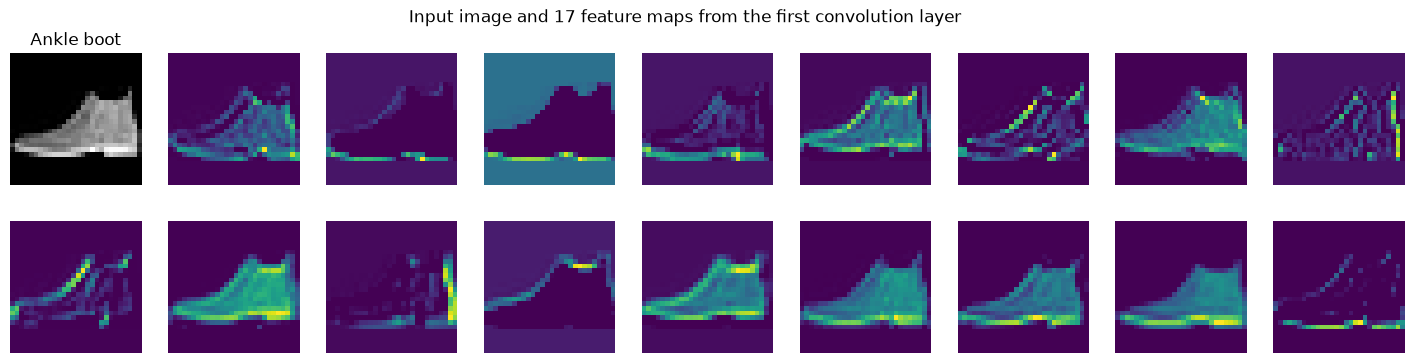

In [12]:
# ===== What the first convolution layer sees =====
first_conv = models.Model(inputs=model.inputs, outputs=model.layers[0].output)
maps = first_conv.predict(x_test[:1], verbose=0)[0]

fig, axes = plt.subplots(2, 9, figsize=(18, 4))
axes[0, 0].imshow(x_test[0, :, :, 0], cmap='gray'); axes[0, 0].set_title(class_names[y_test[0]])
for i, ax in enumerate(axes.flat[1:]):
    ax.imshow(maps[:, :, i], cmap='viridis')
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('Input image and 17 feature maps from the first convolution layer')
plt.show()